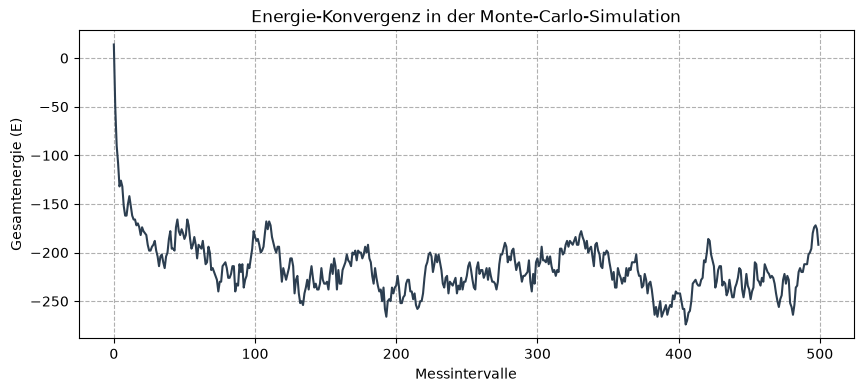

Simulation erfolgreich abgeschlossen. Daten strukturiert exportiert.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parameter-Setup (Mikroskopisches System)
N = 20  # Gittergröße (20x20)
T = 2.5  # Temperatur
steps = 50000  # Monte-Carlo-Schritte

# Initialisierung: Zufälliges Gitter (+1 oder -1)
gitter = np.random.choice([-1, 1], size=(N, N))

def berechne_energie(gitter):
    """Berechnet die Gesamtenergie des Gitters (Nächste-Nachbar-Interaktion)"""
    energie = 0
    for i in range(N):
        for j in range(N):
            S = gitter[i, j]
            # Periodische Randbedingungen (Morrow-Nachbarn)
            nachbarn = gitter[(i+1)%N, j] + gitter[i, (j+1)%N] + gitter[(i-1)%N, j] + gitter[i, (j-1)%N]
            energie += -S * nachbarn
    return energie / 4.0

# 2. Metropolis-Algorithmus (Monte-Carlo-Simulation)
energien = []
for step in range(steps):
    # Zufälligen Punkt im Gitter auswählen
    x, y = np.random.randint(0, N), np.random.randint(0, N)
    S = gitter[x, y]
    
    # Energieänderung berechnen, falls der Spin umgedreht wird
    # Korrekte Berechnung mit periodischen Randbedingungen (x,y)
    nachbarn = gitter[(x+1)%N, y] + gitter[x, (y+1)%N] + gitter[(x-1)%N, y] + gitter[x, (y-1)%N]
    dE = 2 * S * nachbarn
    
    # Metropolis-Kriterium anwenden
    if dE <= 0 or np.random.rand() < np.exp(-dE / T):
        gitter[x, y] = -S  # Spin umdrehen
        
    if step % 100 == 0:
        energien.append(berechne_energie(gitter))

# 3. Visualisierung der Ergebnisse
plt.figure(figsize=(10, 4))
plt.plot(energien, color='#2c3e50', lw=1.5)
plt.title('Energie-Konvergenz in der Monte-Carlo-Simulation')
plt.xlabel('Messintervalle')
plt.ylabel('Gesamtenergie (E)')
plt.grid(True, linestyle='--')
plt.savefig('monte_carlo_convergence.png')
plt.show()

print("Simulation erfolgreich abgeschlossen. Daten strukturiert exportiert.")